# DeepJSCC + NTSCC Windows benchmark (final repaired)

This notebook is a clean, ordered benchmark. It preserves both official checkpoints, runs native CPU inference on Windows, uses a common image/resolution/SNR/seeds, exercises the team's real 5G-LDPC/QPSK/AWGN path, and only then evaluates two separately calibrated K=256 latent codebooks. Analog symbols, entropy estimates, packet bits, coded bits, and complex channel uses are kept distinct.

# UPDATED RESULTS DASHBOARD

This is the newly executed comparison using the rate-conditioned PQ4 K=256 NTSCC codebook. The complete wrapper source and executed five-seed PHY evaluation remain in **Section 9** at the end of this notebook. The table and three plots below are embedded outputs, so they are visible without rerunning the notebook.

,Model,Algorithm,Original image packets,Latent representation units,CBR,PSNR (dB),SSIM,LPIPS,Reconstruction bits,Latent bits,Compression/payload bits,Complex channel uses,Computational complexity,Measured latency (s),Notes,Coded bits,BPP,Latent MSE,Frame success rate,Fit latency (s)
0,RAW,8-bit RGB + CRC + rate-1/2 LDPC + QPSK + AWGN,1,N/A,8.000868,inf,1.000000,0.000000,9437184,N/A,9437184.0,9438208,LDPC decoding is iterative in coded blocks and...,275.233631,No latent representation; one channel trial.,18876416.0,24.0,N/A,1.0,N/A
1,JPEG Q90,JPEG quality 90 + CRC + rate-1/2 LDPC + QPSK +...,1,N/A,1.123264,36.230540,0.973055,0.006834,9437184,N/A,1324216.0,1325056,Block-DCT JPEG plus iterative LDPC decoding,192.334255,Compressed payload bits are not latent-model b...,2650112.0,3.3676554361979165,N/A,1.0,N/A
2,JPEG Q75,JPEG quality 75 + CRC + rate-1/2 LDPC + QPSK +...,1,N/A,0.690104,32.156016,0.943577,0.018946,9437184,N/A,813912.0,814080,Block-DCT JPEG plus iterative LDPC decoding,94.444091,Compressed payload bits are not latent-model b...,1628160.0,2.06988525390625,N/A,1.0,N/A
3,JPEG Q50,JPEG quality 50 + CRC + rate-1/2 LDPC + QPSK +...,1,N/A,0.469618,29.425811,0.910267,0.043609,9437184,N/A,552960.0,553984,Block-DCT JPEG plus iterative LDPC decoding,32.784179,Compressed payload bits are not latent-model b...,1107968.0,1.40625,N/A,1.0,N/A
4,JPEG Q25,JPEG quality 25 + CRC + rate-1/2 LDPC + QPSK +...,1,N/A,0.310764,26.841379,0.861148,0.087909,9437184,N/A,366488.0,366592,Block-DCT JPEG plus iterative LDPC decoding,22.463632,Compressed payload bits are not latent-model b...,733184.0,0.9320271809895834,N/A,1.0,N/A
5,DeepJSCC,Tiled learned analog JSCC,24,20184.0,0.162547,15.983024,0.410914,0.702314,9437184,N/A,N/A,191748,Encoder/decoder neural inference per image tile,22.144666,Continuous channel symbols have no mathematica...,N/A,N/A,N/A,N/A,N/A
6,NTSCC,Rate-adaptive nonlinear transform source-chann...,1,1536.0,0.030624,25.705845,0.820711,0.169477,9437184,312749.86962890625,312749.86962890625,36126,Analysis/hyperprior/rate-adapter/decoder neura...,51.768804,"Entropy-estimated bits are diagnostic, not tra...",N/A,0.7953640483319759,N/A,N/A,N/A
7,DeepJSCC codebook,K=256 full-token vector quantization + LDPC/QP...,24,20184.0,0.137153,17.214867,0.393513,0.609005,9437184,161472.0,161632.0,161792,K-means nearest-centroid search O(N*K*D) plus ...,12.299274,Payload also includes packet metadata and CRC.,323584.0,0.4110514322916667,0.03875836357474327,1.0,N/A
8,NTSCC codebook,Rate-conditioned PQ4 K=256 (exact partial dime...,1,18064.0,0.128472,24.313332,0.796874,0.185390,9437184,144512.0,150944.0,151552,Rate-conditioned nearest-centroid PQ4 O(N_acti...,32.068559,Selected measured Pareto-knee wrapper; payload...,303104.0,0.3838704427083333,0.37200748282920004,1.0,9.01109499996528


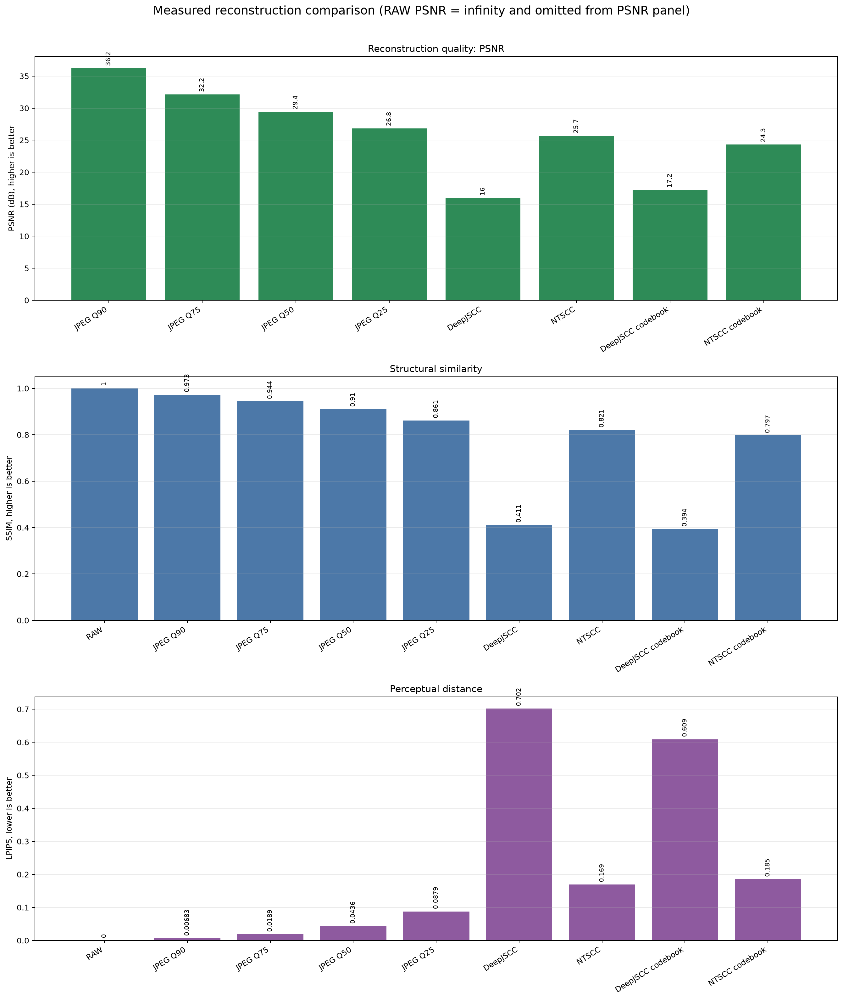

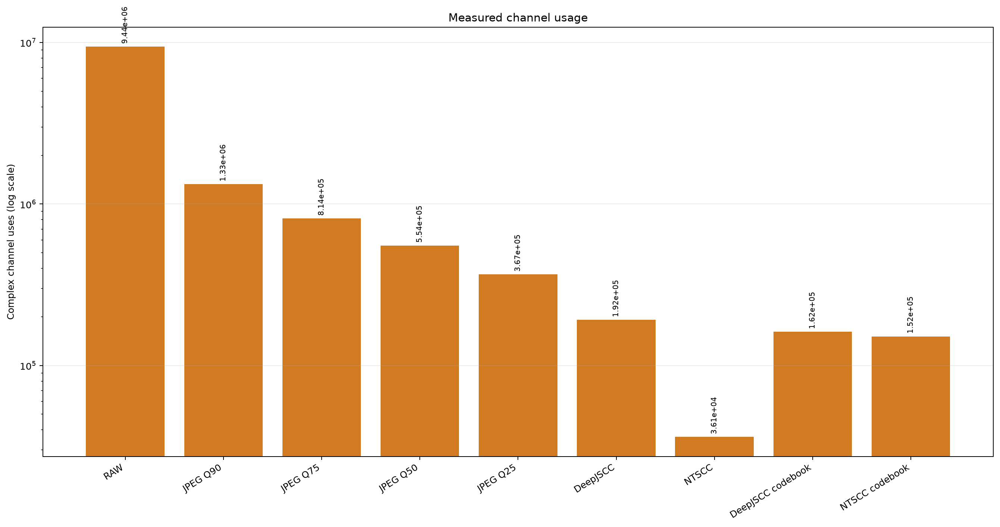

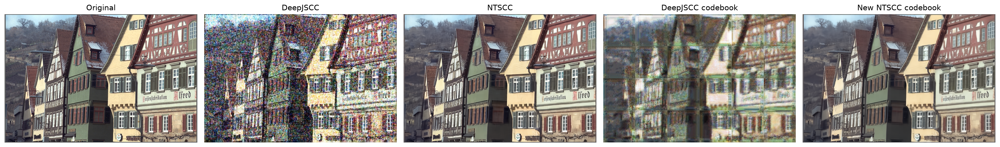

In [3]:
from IPython.display import display, Image as DisplayImage
integrated_dir = Path.cwd() / 'benchmark_outputs' / 'integrated_rate_conditioned_comparison'
integrated_kpis = pd.read_csv(integrated_dir / 'all_methods_kpi_table.csv', keep_default_na=False)
display(integrated_kpis)
display(DisplayImage(filename=str(integrated_dir / 'all_methods_quality_ssim_lpips.png')))
display(DisplayImage(filename=str(integrated_dir / 'all_methods_channel_usage.png')))
display(DisplayImage(filename=str(integrated_dir / 'all_learned_reconstructions.png')))


In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd().resolve()
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / '.matplotlib'))
assert Path(sys.prefix).resolve() == (ROOT / '.venv').resolve(), 'Select the semcom-windows kernel created by setup_windows_venv.ps1'
from IPython.display import display, Image as DisplayImage
from semcom_benchmark.session import BenchmarkSession
session = BenchmarkSession(ROOT, snr_db=10.0, seeds=(42, 43, 44, 45, 46), device='cpu')
print(f'Python: {sys.version.split()[0]} | environment: {sys.prefix}')
print(f'Test image: {session.image_path.name}, {session.width}x{session.height}')

Python: 3.13.4 | environment: D:\<local OneDrive>\Desktop\image_semcom\.venv
Test image: kodim08.png, 768x512


## 1. Provenance and strict checkpoint validation

The adapters instantiate checkpoint-compatible official architectures. Learned keys and shapes must match. `strict=False` is never used. Only the six official Swin attention masks listed below may be regenerated for the runtime resolution.

In [2]:
checkpoint_validation = session.load_models()
display(checkpoint_validation)

D:\<local OneDrive>\Desktop\image_semcom\.venv\Lib\site-packages\timm\models\layers\__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
D:\<local OneDrive>\Desktop\image_semcom\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
D:\<local OneDrive>\Desktop\image_semcom\.venv\Lib\site-packages\torch\jit\_script.py:365: FutureWarning: `torch.jit.script_method` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
D:\<local OneDrive>\Desktop\image_semcom\.venv\Lib\site-packages\torch\functional.py:504: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\n

Encoder  dim=256, input_resolution=(256, 256), depth=1
Encoder  dim=256, input_resolution=(128, 128), depth=1
Encoder  dim=256, input_resolution=(64, 64), depth=2
Encoder  dim=256, input_resolution=(32, 32), depth=4


Decoder  dim=256, input_resolution=(16, 16), depth=4
Decoder  dim=256, input_resolution=(32, 32), depth=2
Decoder  dim=256, input_resolution=(64, 64), depth=1
Decoder  dim=256, input_resolution=(128, 128), depth=1


CONFIG RATE tensor([ 16,  32,  48,  64,  80,  96, 102, 118, 134, 160, 186, 192, 208, 224,
        240, 256])


{'DeepJSCC': {'checkpoint_key_count': 29,
  'missing_keys': [],
  'unexpected_keys': [],
  'shape_mismatches': {},
  'skipped_regenerated_buffers': [],
  'strict_load': True,
  'checkpoint_sha256': '00b33bac630555d9a0d72a76d0fea9103cef9a38df0d5547be53c5320a451d44',
  'source_commit': 'e1cef6aeadedde9ff359760936a2ddf2540dd821'},
 'NTSCC': {'checkpoint_key_count': 426,
  'missing_keys': [],
  'unexpected_keys': [],
  'shape_mismatches': {},
  'skipped_regenerated_buffers': ['ga.layers.2.blocks.1.attn_mask',
   'ga.layers.3.blocks.1.attn_mask',
   'ga.layers.3.blocks.3.attn_mask',
   'gs.layers.0.blocks.1.attn_mask',
   'gs.layers.0.blocks.3.attn_mask',
   'gs.layers.1.blocks.1.attn_mask'],
  'strict_load': True,
  'checkpoint_sha256': '7a8d1990dbd678ea5d3daa02c3aeaaf4459b347a96d6aa81a5c02eae6bfc7323',
  'source_commit': 'dd3c745374023af6d01f465c379122be785d936f'}}

## 2. Official DeepJSCC and NTSCC inference

Both models use the same 768x512 RGB image, evaluation SNR 10 dB, and five noise seeds. DeepJSCC's 128x128 checkpoint is applied by documented reflect-pad/tile/crop; its continuous real channel symbols are paired into complex channel uses. NTSCC entropy BPP remains a diagnostic estimate and is not labeled as radio bits.

In [3]:
native_results = session.run_native_models()
display(native_results[['method','checkpoint_training_snr_db','evaluation_snr_db','complex_channel_uses','cbr','psnr_db_mean','psnr_db_std','ssim_mean','ssim_std','lpips_mean','clip_cosine_mean']])

Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]


D:\<local OneDrive>\Desktop\image_semcom\.venv\Lib\site-packages\torchvision\models\_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
D:\<local OneDrive>\Desktop\image_semcom\.venv\Lib\site-packages\torchvision\models\_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Loading model from: D:\<local OneDrive>\Desktop\image_semcom\.venv\Lib\site-packages\lpips\weights\v0.1\alex.pth


D:\<local OneDrive>\Desktop\image_semcom\.venv\Lib\site-packages\clip\clip.py:6: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import packaging


D:\<local OneDrive>\Desktop\image_semcom\.venv\Lib\site-packages\torch\jit\_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


,method,checkpoint_training_snr_db,evaluation_snr_db,complex_channel_uses,cbr,psnr_db_mean,psnr_db_std,ssim_mean,ssim_std,lpips_mean,clip_cosine_mean
0,DeepJSCC,200.0,10.0,191748,0.162547,15.983024,0.017816,0.410914,0.001496,0.702314,0.777739
1,NTSCC,10.0,10.0,36126,0.030624,25.705845,0.044682,0.820711,0.000897,0.169477,0.967443


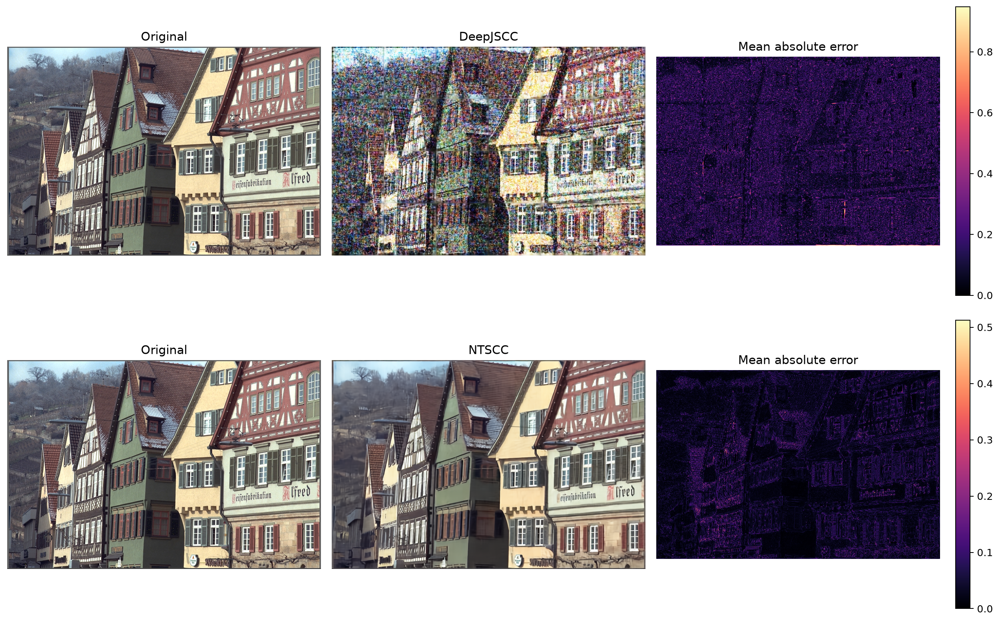

In [4]:
native_plot = session.plot_native_reconstructions()
display(DisplayImage(filename=str(native_plot)))

## 3. RAW/JPEG digital baselines through the team PHY

Payloads are framed with CRC, encoded by the team's Sionna 5G LDPC implementation, QPSK-modulated, passed through AWGN, decoded, and CRC-checked. Quality metrics are recorded only for successful frames. LDPC redundancy is reported separately and is never treated as compression. The very large full-resolution RAW payload uses one auditable CPU trial; every JPEG quality uses all five seeds.

In [5]:
digital_results = session.run_digital_baselines()
display(digital_results[['method','payload_bits','coded_bits','complex_channel_uses','cbr','frame_success_rate','compression_ratio_vs_raw','psnr_db_mean','ssim_mean','lpips_mean','clip_cosine_mean']])

,method,payload_bits,coded_bits,complex_channel_uses,cbr,frame_success_rate,compression_ratio_vs_raw,psnr_db_mean,ssim_mean,lpips_mean,clip_cosine_mean
0,RAW + LDPC/QPSK/AWGN,9437184,18876416,9438208,8.000868,1.0,1.000000,inf,1.000000,0.000000,1.000000
1,JPEG Q90 + LDPC/QPSK/AWGN,1324216,2650112,1325056,1.123264,1.0,7.126620,36.230540,0.973055,0.006834,0.987068
2,JPEG Q75 + LDPC/QPSK/AWGN,813912,1628160,814080,0.690104,1.0,11.594846,32.156016,0.943577,0.018946,0.985519
3,JPEG Q50 + LDPC/QPSK/AWGN,552960,1107968,553984,0.469618,1.0,17.066667,29.425811,0.910267,0.043609,0.972427
4,JPEG Q25 + LDPC/QPSK/AWGN,366488,733184,366592,0.310764,1.0,25.750322,26.841379,0.861148,0.087909,0.951306


In [6]:
pre_codebook_table = session.comparison_table()
display(pre_codebook_table.fillna('N/A'))

,Method,Category,Payload bits,Coded bits,Complex channel uses,CBR,Compression vs RAW,Bit reduction vs RAW (%),Channel-use saving vs RAW (%),Frame success rate,PSNR mean (dB),PSNR std,SSIM mean,LPIPS mean,CLIP cosine mean,Warning
0,RAW image,Source,9437184.0,N/A,N/A,N/A,1.0,0.0,N/A,N/A,inf,0.0,1.000000,0.000000,1.000000,Untransmitted source reference.
1,JPEG Q90,Codec only,1324216.0,N/A,N/A,N/A,7.12662,85.968102,N/A,N/A,36.230540,N/A,0.973055,0.006834,0.987068,Codec distortion only; no channel.
2,JPEG Q75,Codec only,813912.0,N/A,N/A,N/A,11.594846,91.375478,N/A,N/A,32.156016,N/A,0.943577,0.018946,0.985519,Codec distortion only; no channel.
3,JPEG Q50,Codec only,552960.0,N/A,N/A,N/A,17.066667,94.140625,N/A,N/A,29.425811,N/A,0.910267,0.043609,0.972427,Codec distortion only; no channel.
4,JPEG Q25,Codec only,366488.0,N/A,N/A,N/A,25.750322,96.116553,N/A,N/A,26.841379,N/A,0.861148,0.087909,0.951306,Codec distortion only; no channel.
5,RAW + LDPC/QPSK/AWGN,Digital PHY,9437184.0,18876416.0,9438208.0,8.000868,1.0,0.0,0.0,1.0,inf,0.0,1.000000,0.000000,1.000000,Metrics include successful CRC-valid frames on...
6,JPEG Q90 + LDPC/QPSK/AWGN,Digital PHY,1324216.0,2650112.0,1325056.0,1.123264,7.12662,85.968102,85.960725,1.0,36.230540,0.0,0.973055,0.006834,0.987068,Metrics include successful CRC-valid frames on...
7,JPEG Q75 + LDPC/QPSK/AWGN,Digital PHY,813912.0,1628160.0,814080.0,0.690104,11.594846,91.375478,91.374634,1.0,32.156016,0.0,0.943577,0.018946,0.985519,Metrics include successful CRC-valid frames on...
8,JPEG Q50 + LDPC/QPSK/AWGN,Digital PHY,552960.0,1107968.0,553984.0,0.469618,17.066667,94.140625,94.130411,1.0,29.425811,0.0,0.910267,0.043609,0.972427,Metrics include successful CRC-valid frames on...
9,JPEG Q25 + LDPC/QPSK/AWGN,Digital PHY,366488.0,733184.0,366592.0,0.310764,25.750322,96.116553,96.115873,1.0,26.841379,0.0,0.861148,0.087909,0.951306,Metrics include successful CRC-valid frames on...


# 4. Codebook approaches (intentionally after the official comparison)

DeepJSCC and NTSCC receive separate K=256 codebooks fitted only on real CIFAR-10 training-split calibration latents. The test image is never used for fitting, and official encoders/decoders remain frozen. Packets use the team repository format and contain indices, latent metadata, NTSCC rate data where needed, and CRC.

In [7]:
codebook_provenance = session.fit_codebooks(calibration_images=8)
packets = session.prepare_codebook_packets()
display(codebook_provenance)
print({name: packet.bits.size for name, packet in packets.items()})

{'dataset': 'CIFAR-10 training split',
 'dataset_root': 'D:\\<local OneDrive>\\Desktop\\image_semcom\\data',
 'selected_training_indices': [0, 1, 2, 3, 4, 5, 6, 7],
 'calibration_resize': [128, 128],
 'test_image_used_for_fit': False,
 'deepjscc_codebook_sha256': '7924944c1201260256eea1b47bcd990d820f3586ef01a9d6a53d8ae7ea0151c1',
 'ntscc_codebook_sha256': '1adac6882c5f9104436049b64206af40de9ecbaa6263ad1e124716d4c303f789',
 'ntscc_codebook_design': 'K=256 active-prefix product quantization with 16-D blocks',
 'ntscc_calibration_active_block_count': 1129,
 'separate_codebooks': True,
 'official_encoders_decoders_frozen': True,
 'fit_latency_s': 7.569245099963155}

{'DeepJSCC codebook': 161632, 'NTSCC codebook': 42440}


### 4a. Noiseless quantization ablation (first)

In [8]:
noiseless_codebooks = session.run_noiseless_codebook_ablation()
display(noiseless_codebooks)

,method,experiment,packet_bits,shared_codebook_storage_bits,quantization_mse,latency_s,codebook_utilization,used_entries,dead_entries,perplexity,mse,psnr_db,ssim,lpips,clip_cosine
0,DeepJSCC codebook,noiseless quantization ablation,161632,155648,0.038758,0.830407,0.925781,237,19,125.459049,0.018989,17.214867,0.393513,0.609005,0.611349
1,NTSCC codebook,noiseless quantization ablation,42440,131072,2.122081,4.612358,0.988281,253,3,192.832008,0.041617,13.807251,0.383858,0.517441,0.608645


### 4b. Real codebook packets through LDPC/QPSK/AWGN (second)

All five seeds are retained. CRC/frame failures remain failures with N/A reconstruction quality; they are never replaced by codec-only results.

In [9]:
noisy_codebooks = session.run_noisy_codebook_transport()
display(noisy_codebooks[['method','packet_bits','coded_bits','complex_channel_uses','cbr','frame_success_rate','codebook_utilization','dead_entries','perplexity','quantization_mse','psnr_db_mean','ssim_mean','lpips_mean','clip_cosine_mean']])

,method,packet_bits,coded_bits,complex_channel_uses,cbr,frame_success_rate,codebook_utilization,dead_entries,perplexity,quantization_mse,psnr_db_mean,ssim_mean,lpips_mean,clip_cosine_mean
0,DeepJSCC codebook,161632,323584,161792,0.137153,1.0,0.925781,19,125.459049,0.038758,17.214867,0.393513,0.609005,0.611349
1,NTSCC codebook,42440,86016,43008,0.036458,1.0,0.988281,3,192.832008,2.122081,13.807251,0.383858,0.517441,0.608645


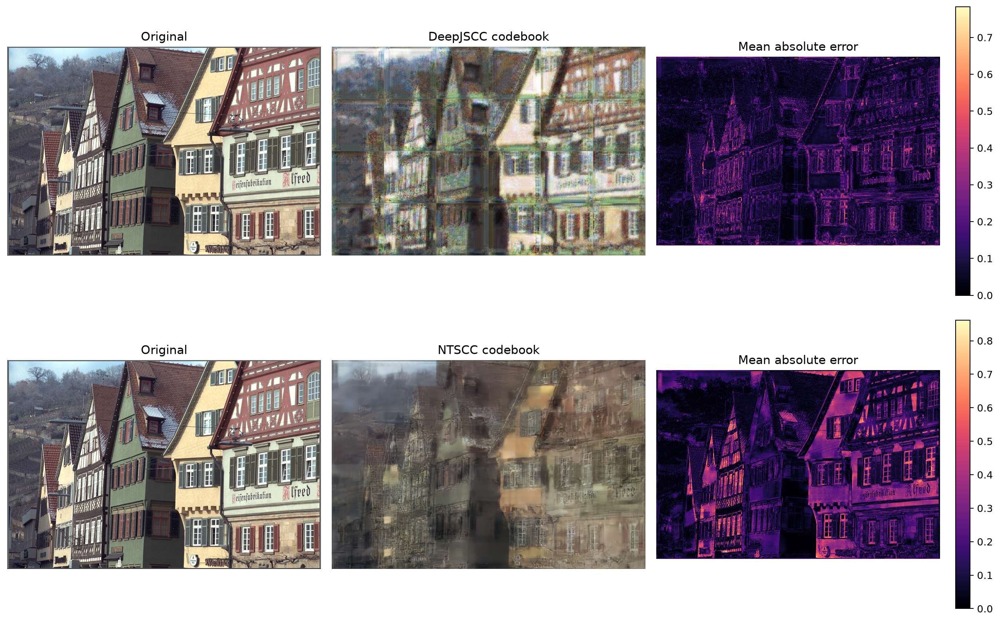

In [10]:
codebook_plot = session.plot_codebook_reconstructions()
display(DisplayImage(filename=str(codebook_plot)))

## 5. Final repaired comparison

`N/A` is used where a quantity has no valid interpretation. In particular, native analog JSCC has no payload-bit compression ratio, and NTSCC entropy BPP is not promoted to actual transmitted radio bits.

,Method,Category,Payload bits,Coded bits,Complex channel uses,CBR,Compression vs RAW,Bit reduction vs RAW (%),Channel-use saving vs RAW (%),Frame success rate,PSNR mean (dB),PSNR std,SSIM mean,LPIPS mean,CLIP cosine mean,Warning
0,RAW image,Source,9437184.0,N/A,N/A,N/A,1.0,0.0,N/A,N/A,inf,0.0,1.000000,0.000000,1.000000,Untransmitted source reference.
1,JPEG Q90,Codec only,1324216.0,N/A,N/A,N/A,7.12662,85.968102,N/A,N/A,36.230540,N/A,0.973055,0.006834,0.987068,Codec distortion only; no channel.
2,JPEG Q75,Codec only,813912.0,N/A,N/A,N/A,11.594846,91.375478,N/A,N/A,32.156016,N/A,0.943577,0.018946,0.985519,Codec distortion only; no channel.
3,JPEG Q50,Codec only,552960.0,N/A,N/A,N/A,17.066667,94.140625,N/A,N/A,29.425811,N/A,0.910267,0.043609,0.972427,Codec distortion only; no channel.
4,JPEG Q25,Codec only,366488.0,N/A,N/A,N/A,25.750322,96.116553,N/A,N/A,26.841379,N/A,0.861148,0.087909,0.951306,Codec distortion only; no channel.
5,RAW + LDPC/QPSK/AWGN,Digital PHY,9437184.0,18876416.0,9438208.0,8.000868,1.0,0.0,0.0,1.0,inf,0.0,1.000000,0.000000,1.000000,Metrics include successful CRC-valid frames on...
6,JPEG Q90 + LDPC/QPSK/AWGN,Digital PHY,1324216.0,2650112.0,1325056.0,1.123264,7.12662,85.968102,85.960725,1.0,36.230540,0.0,0.973055,0.006834,0.987068,Metrics include successful CRC-valid frames on...
7,JPEG Q75 + LDPC/QPSK/AWGN,Digital PHY,813912.0,1628160.0,814080.0,0.690104,11.594846,91.375478,91.374634,1.0,32.156016,0.0,0.943577,0.018946,0.985519,Metrics include successful CRC-valid frames on...
8,JPEG Q50 + LDPC/QPSK/AWGN,Digital PHY,552960.0,1107968.0,553984.0,0.469618,17.066667,94.140625,94.130411,1.0,29.425811,0.0,0.910267,0.043609,0.972427,Metrics include successful CRC-valid frames on...
9,JPEG Q25 + LDPC/QPSK/AWGN,Digital PHY,366488.0,733184.0,366592.0,0.310764,25.750322,96.116553,96.115873,1.0,26.841379,0.0,0.861148,0.087909,0.951306,Metrics include successful CRC-valid frames on...


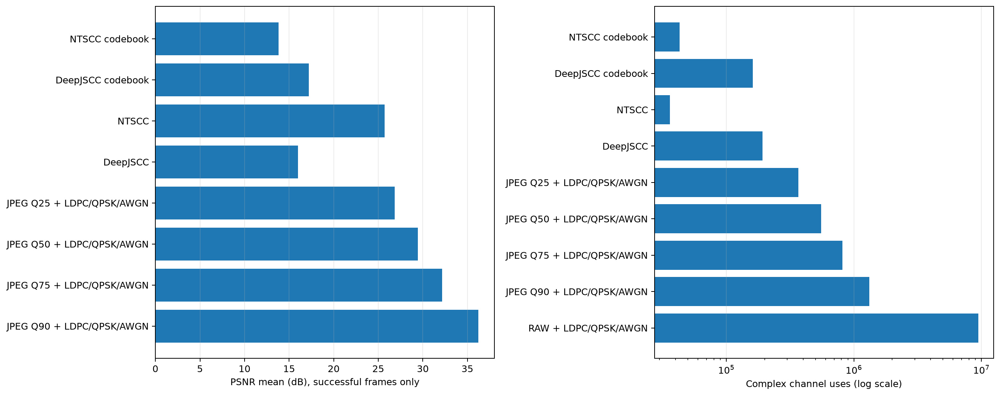

Results: D:\<local OneDrive>\Desktop\image_semcom\benchmark_outputs\final_repaired


In [11]:
final_table = session.comparison_table()
display(final_table.fillna('N/A'))
comparison_plot = session.plot_comparison(final_table)
display(DisplayImage(filename=str(comparison_plot)))
print(f'Results: {session.output_dir}')

## 6. Final presentation plots (measured outputs only)

These figures read `benchmark_outputs/final_repaired/final_comparison.csv` only. They do not rerun a model, metric network, LDPC decoder or channel. JPEG quality bars are codec-only; JPEG channel-resource bars explicitly represent JPEG + LDPC/QPSK/AWGN. RAW is an exact reconstruction and is not assigned a fabricated finite PSNR. LPIPS and CLIP remain in the detailed table.

,Method,Category,Payload bits,Coded bits,Complex channel uses,CBR,Compression vs RAW,Bit reduction vs RAW (%),Channel-use saving vs RAW (%),Frame success rate,PSNR mean (dB),PSNR std,SSIM mean,LPIPS mean,CLIP cosine mean,Warning
Method,,,,,,,,,,,,,,,,
RAW image,RAW image,Source,9437184.0,N/A,N/A,N/A,1.0,0.0,N/A,N/A,inf,0.0,1.000000,0.000000,1.000000,Untransmitted source reference.
JPEG Q90,JPEG Q90,Codec only,1324216.0,N/A,N/A,N/A,7.12662,85.968102,N/A,N/A,36.230540,N/A,0.973055,0.006834,0.987068,Codec distortion only; no channel.
JPEG Q75,JPEG Q75,Codec only,813912.0,N/A,N/A,N/A,11.594846,91.375478,N/A,N/A,32.156016,N/A,0.943577,0.018946,0.985519,Codec distortion only; no channel.
JPEG Q50,JPEG Q50,Codec only,552960.0,N/A,N/A,N/A,17.066667,94.140625,N/A,N/A,29.425811,N/A,0.910267,0.043609,0.972427,Codec distortion only; no channel.
JPEG Q25,JPEG Q25,Codec only,366488.0,N/A,N/A,N/A,25.750322,96.116553,N/A,N/A,26.841379,N/A,0.861148,0.087909,0.951306,Codec distortion only; no channel.
RAW + LDPC/QPSK/AWGN,RAW + LDPC/QPSK/AWGN,Digital PHY,9437184.0,18876416.0,9438208.0,8.000868,1.0,0.0,0.0,1.0,inf,0.0,1.000000,0.000000,1.000000,Metrics include successful CRC-valid frames on...
JPEG Q90 + LDPC/QPSK/AWGN,JPEG Q90 + LDPC/QPSK/AWGN,Digital PHY,1324216.0,2650112.0,1325056.0,1.123264,7.12662,85.968102,85.960725,1.0,36.230540,0.0,0.973055,0.006834,0.987068,Metrics include successful CRC-valid frames on...
JPEG Q75 + LDPC/QPSK/AWGN,JPEG Q75 + LDPC/QPSK/AWGN,Digital PHY,813912.0,1628160.0,814080.0,0.690104,11.594846,91.375478,91.374634,1.0,32.156016,0.0,0.943577,0.018946,0.985519,Metrics include successful CRC-valid frames on...
JPEG Q50 + LDPC/QPSK/AWGN,JPEG Q50 + LDPC/QPSK/AWGN,Digital PHY,552960.0,1107968.0,553984.0,0.469618,17.066667,94.140625,94.130411,1.0,29.425811,0.0,0.910267,0.043609,0.972427,Metrics include successful CRC-valid frames on...


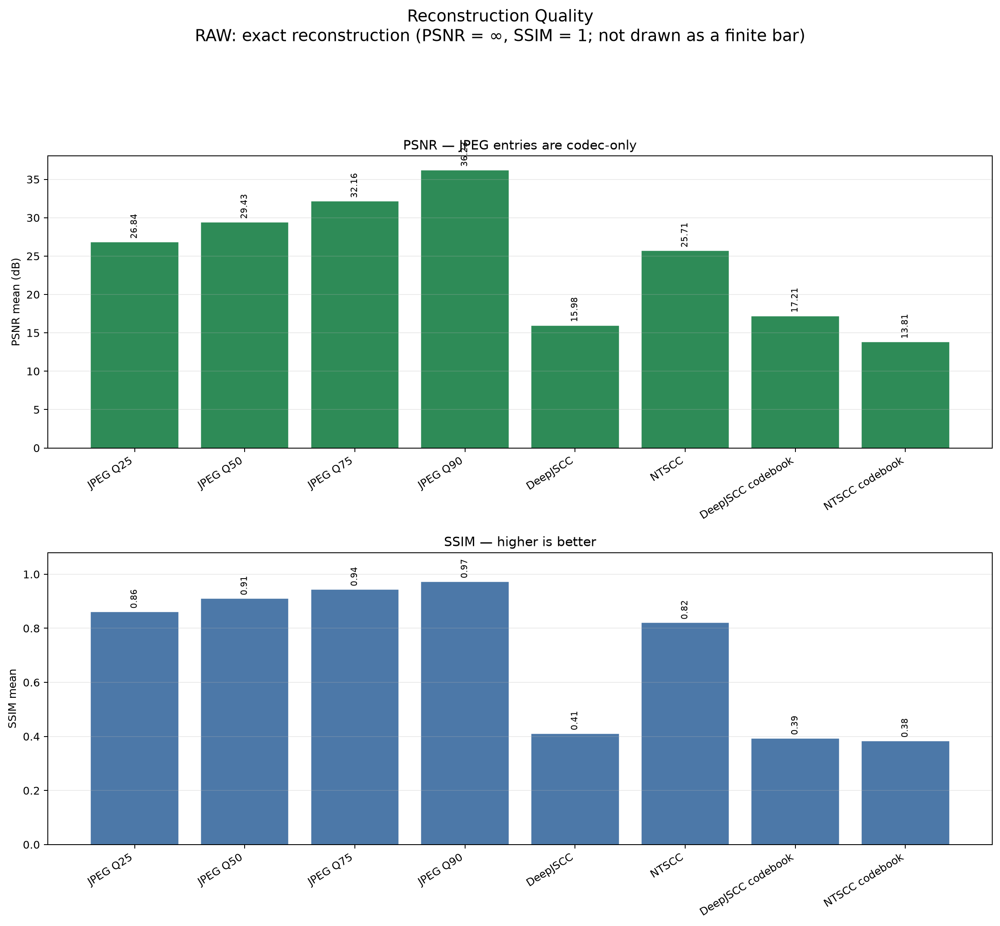

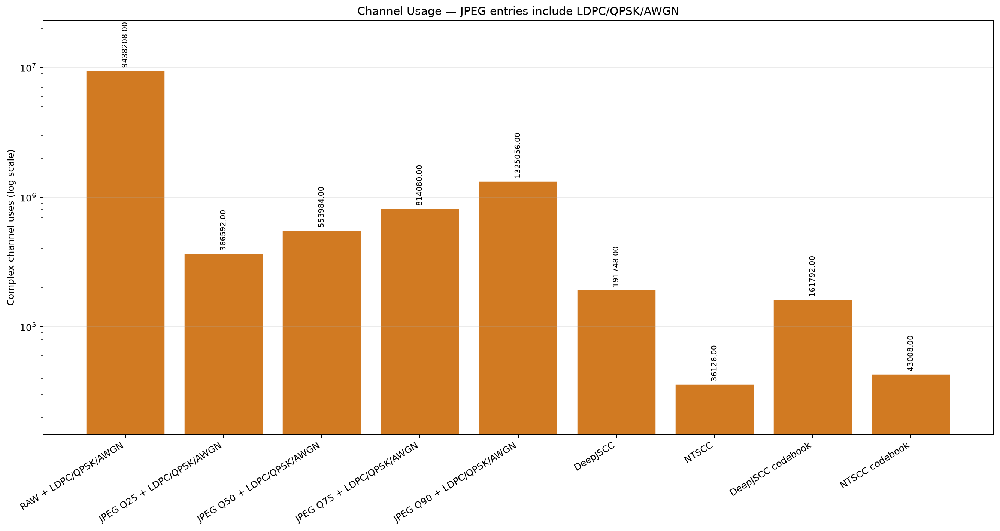

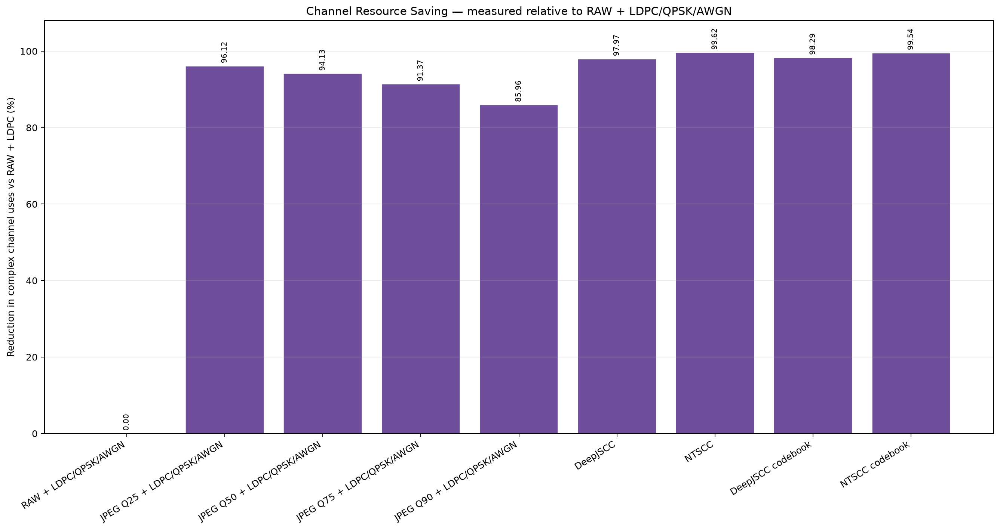

{'reconstruction_quality': 'D:\\<local OneDrive>\\Desktop\\image_semcom\\benchmark_outputs\\final_repaired\\presentation_reconstruction_quality.png',
 'channel_usage': 'D:\\<local OneDrive>\\Desktop\\image_semcom\\benchmark_outputs\\final_repaired\\presentation_channel_usage.png',
 'channel_resource_saving': 'D:\\<local OneDrive>\\Desktop\\image_semcom\\benchmark_outputs\\final_repaired\\presentation_channel_resource_saving.png'}

In [12]:
from pathlib import Path
from IPython.display import display, Image as DisplayImage
from semcom_benchmark.reporting import load_measured_comparison, generate_measured_comparison_plots
validated_output_dir = Path.cwd() / 'benchmark_outputs' / 'final_repaired'
measured_table = load_measured_comparison(validated_output_dir)
presentation_plot_paths = generate_measured_comparison_plots(validated_output_dir)
display(measured_table.fillna('N/A'))
for plot_path in presentation_plot_paths.values():
    display(DisplayImage(filename=plot_path))
presentation_plot_paths

## 7. Consolidated measured comparison and requested figures

All values below come from this execution. `N/A` is retained where a bit count or latent representation is not mathematically defined.


,Model,Algorithm,Original image packets,Latent representation units,CBR,PSNR (dB),SSIM,LPIPS,Reconstruction bits,Latent bits,Compression/payload bits,Complex channel uses,Computational complexity,Measured latency (s),Notes
0,RAW,8-bit RGB + CRC + rate-1/2 LDPC + QPSK + AWGN,1,N/A,8.000868,inf,1.000000,0.000000,9437184,N/A,9437184.0,9438208,LDPC decoding is iterative in coded blocks and...,275.233631,No latent representation; one channel trial.
1,JPEG Q90,JPEG quality 90 + CRC + rate-1/2 LDPC + QPSK +...,1,N/A,1.123264,36.230540,0.973055,0.006834,9437184,N/A,1324216.0,1325056,Block-DCT JPEG plus iterative LDPC decoding,192.334255,Compressed payload bits are not latent-model b...
2,JPEG Q75,JPEG quality 75 + CRC + rate-1/2 LDPC + QPSK +...,1,N/A,0.690104,32.156016,0.943577,0.018946,9437184,N/A,813912.0,814080,Block-DCT JPEG plus iterative LDPC decoding,94.444091,Compressed payload bits are not latent-model b...
3,JPEG Q50,JPEG quality 50 + CRC + rate-1/2 LDPC + QPSK +...,1,N/A,0.469618,29.425811,0.910267,0.043609,9437184,N/A,552960.0,553984,Block-DCT JPEG plus iterative LDPC decoding,32.784179,Compressed payload bits are not latent-model b...
4,JPEG Q25,JPEG quality 25 + CRC + rate-1/2 LDPC + QPSK +...,1,N/A,0.310764,26.841379,0.861148,0.087909,9437184,N/A,366488.0,366592,Block-DCT JPEG plus iterative LDPC decoding,22.463632,Compressed payload bits are not latent-model b...
5,DeepJSCC,Tiled learned analog JSCC,24,20184.0,0.162547,15.983024,0.410914,0.702314,9437184,N/A,N/A,191748,Encoder/decoder neural inference per image tile,22.144666,Continuous channel symbols have no mathematica...
6,NTSCC,Rate-adaptive nonlinear transform source-chann...,1,1536.0,0.030624,25.705845,0.820711,0.169477,9437184,312749.869629,312749.869629,36126,Analysis/hyperprior/rate-adapter/decoder neura...,51.768804,"Entropy-estimated bits are diagnostic, not tra..."
7,DeepJSCC codebook,K=256 full-token vector quantization + LDPC/QP...,24,20184.0,0.137153,17.214867,0.393513,0.609005,9437184,161472.0,161632.0,161792,K-means nearest-centroid search O(N*K*D) plus ...,12.299274,Payload also includes packet metadata and CRC.
8,NTSCC codebook,K=256 active-prefix PQ16 + rate map + LDPC/QPS...,1,4517.0,0.036458,13.807251,0.383858,0.517441,9437184,36136.0,42440.0,43008,Active-block K-means search O(N_active*K*16) p...,20.813137,Only active prefix blocks are clustered; paylo...


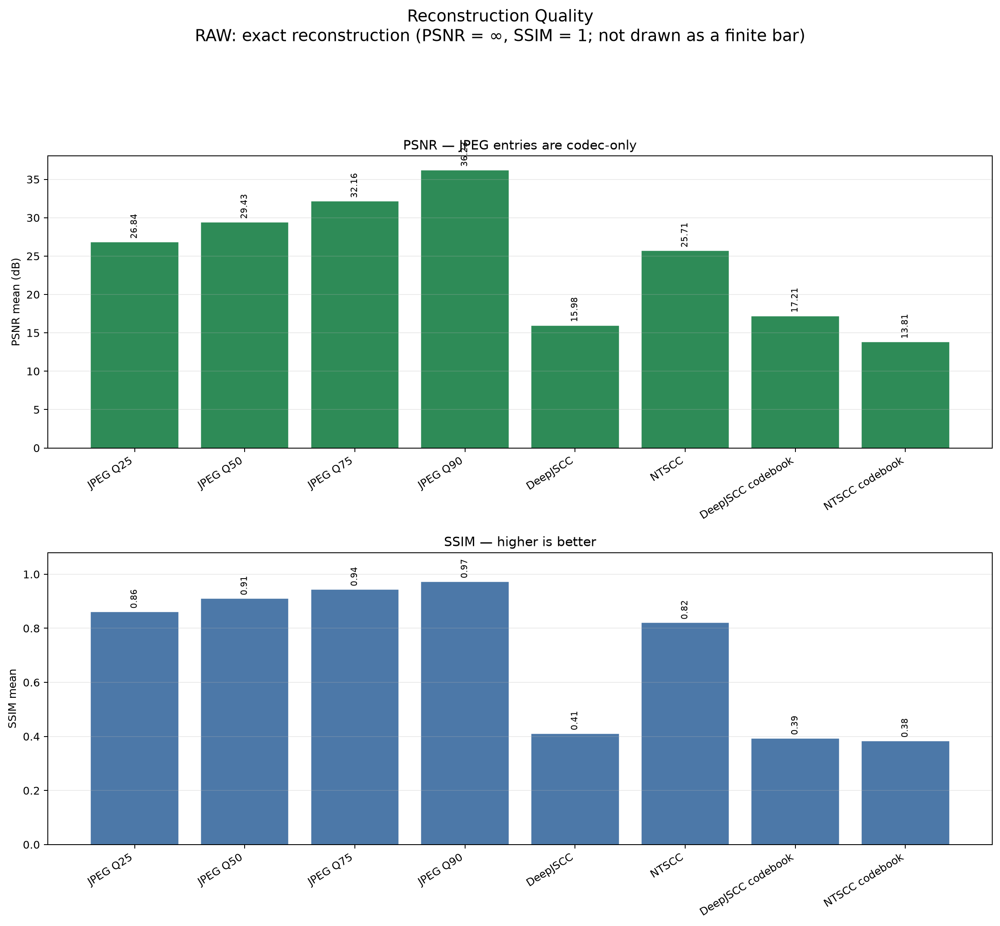

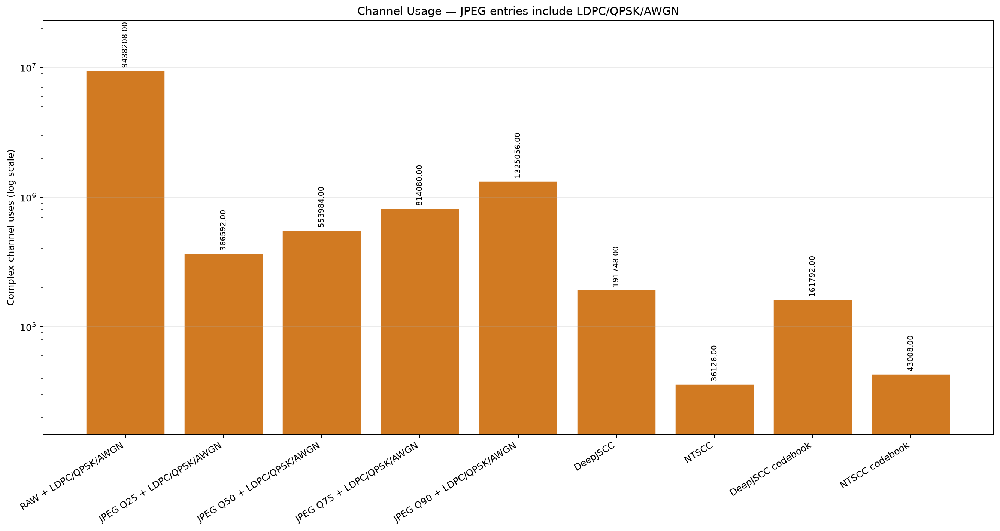

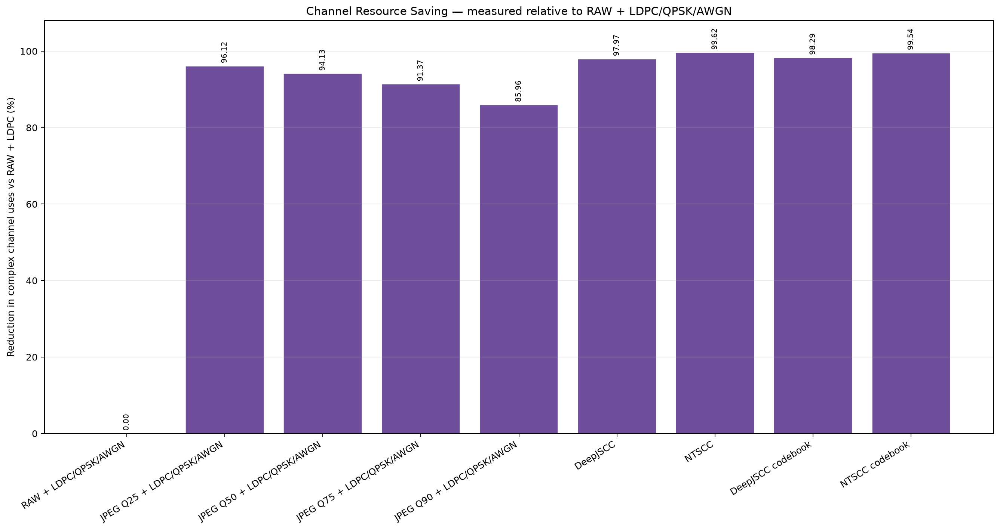

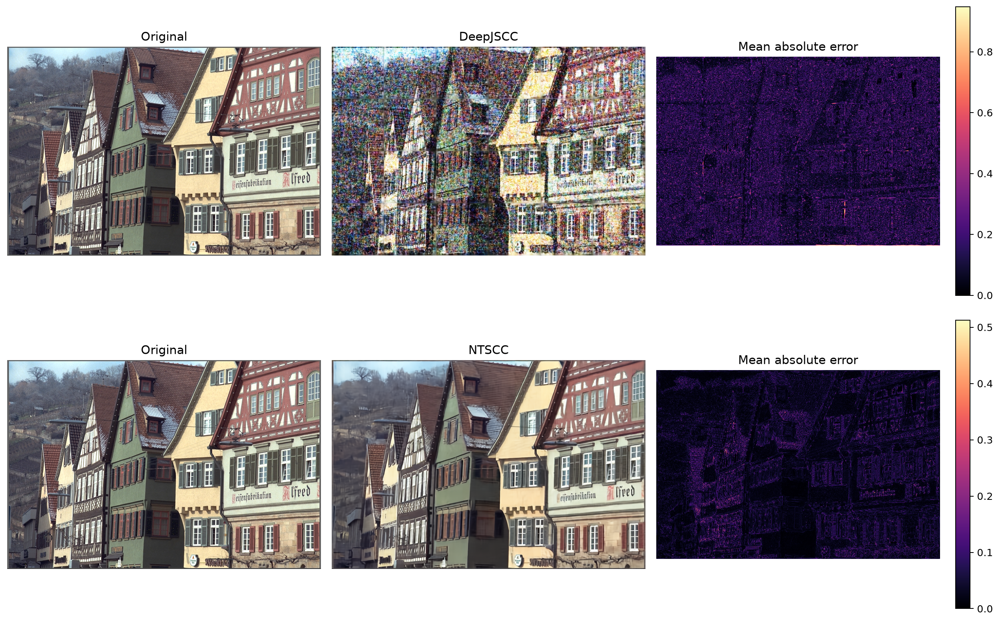

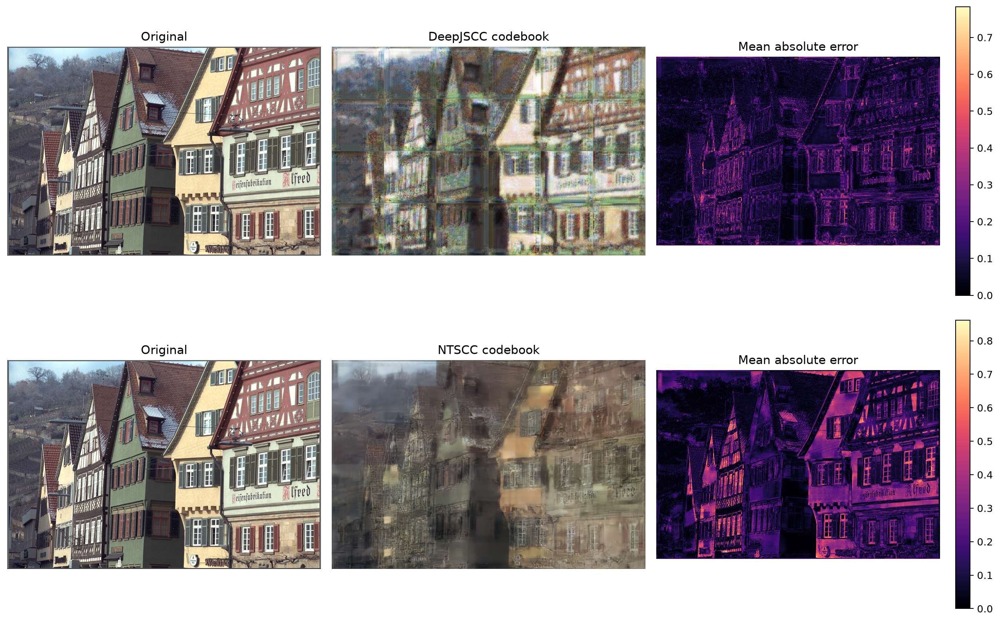

In [13]:
consolidated = session.consolidated_table()
display(consolidated.fillna('N/A'))
display(DisplayImage(filename=str(session.output_dir / 'presentation_reconstruction_quality.png')))
display(DisplayImage(filename=str(session.output_dir / 'presentation_channel_usage.png')))
display(DisplayImage(filename=str(session.output_dir / 'presentation_channel_resource_saving.png')))
display(DisplayImage(filename=str(session.output_dir / 'native_reconstructions.png')))
display(DisplayImage(filename=str(session.output_dir / 'codebook_reconstructions.png')))


## 8. Rate-conditioned NTSCC PQ/RVQ sweep

The original/frozen NTSCC files and the existing benchmark cells above are unchanged. This section loads the separately measured rate-conditioned wrapper sweep. Calibration uses 500 CIFAR-10 training images plus all 23 non-test Kodak images; `kodim08` is excluded.

,configuration,block_size,K,normalized,rvq_stages,psnr_db,ssim,latent_mse_active,total_transmitted_bits,bpp,fit_latency_s,evaluation_latency_s,status
11,rc_pq16_k256_norm,16,256,True,1,15.565445,0.413477,2.015546,42568,0.108256,1.771631,4.823118,ok
12,rc_pq16_k512_norm,16,512,True,1,15.983075,0.451046,1.873459,47085,0.119743,5.324551,4.804955,ok
13,rc_pq16_k1024_norm,16,1024,True,1,17.149546,0.496392,1.735090,51602,0.131231,12.478566,6.045519,ok
3,rc_pq8_k256_norm,8,256,True,1,18.706963,0.609282,1.180227,78688,0.200114,1.954284,6.425796,ok
16,rc_pq8_k256_raw,8,256,False,1,18.626774,0.609036,1.182588,78688,0.200114,1.796956,6.546462,ok
4,rc_pq8_k512_norm,8,512,True,1,20.001381,0.664094,1.008590,87720,0.223083,4.916349,6.011796,ok
17,rc_pq8_k512_raw,8,512,False,1,19.967351,0.662190,1.003693,87720,0.223083,4.481307,6.350014,ok
5,rc_pq8_k1024_norm,8,1024,True,1,20.897842,0.697090,0.864630,96752,0.246053,10.286721,5.380481,ok
14,rc_pq4_k256_raw,4,256,False,1,24.313332,0.796874,0.372007,150944,0.383870,6.190227,14.971743,ok
0,rc_pq4_k256_norm,4,256,True,1,24.203404,0.796740,0.370514,150944,0.383870,6.870750,18.559144,ok


,latent_max_abs_error,rate_map_equal,reconstruction_max_abs_error,direct_metrics,wrapped_metrics,passed
0,0.0,True,0.0,"{'mse': 0.0019432554254308343, 'psnr_db': 27.1...","{'mse': 0.0019432554254308343, 'psnr_db': 27.1...",True


Selected Pareto-knee configuration: rc_pq4_k256_raw


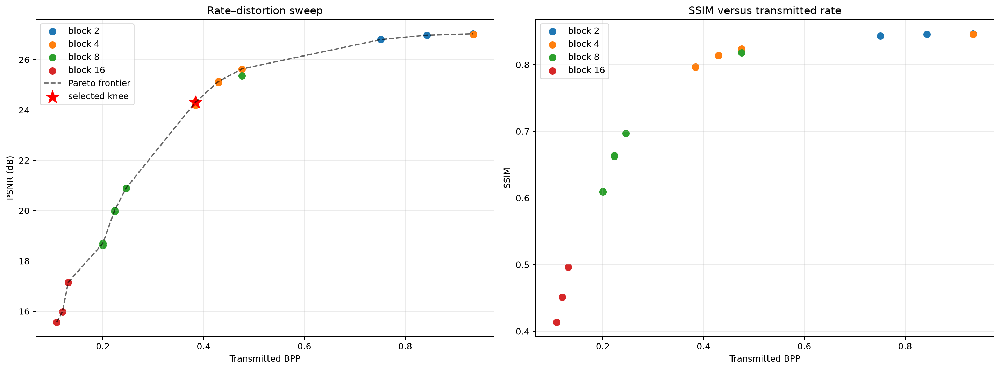

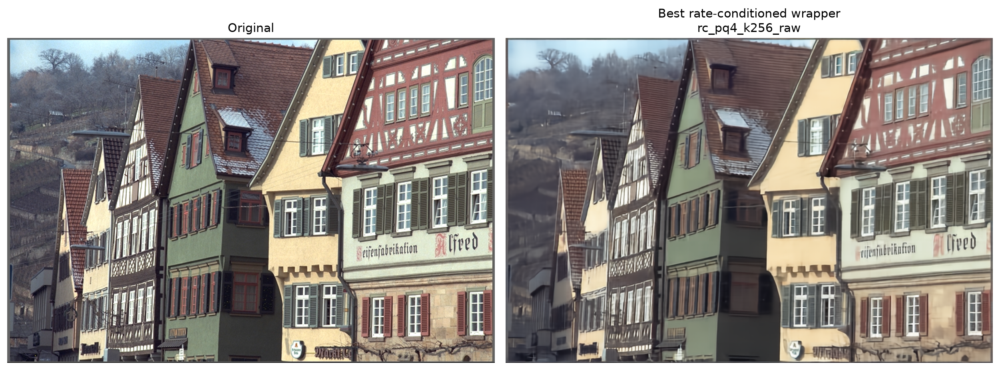

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image as DisplayImage
sweep_dir = Path.cwd() / 'benchmark_outputs' / 'ntscc_rate_conditioned_sweep'
sweep_results = pd.read_csv(sweep_dir / 'sweep_results.csv')
identity_check = json.loads((sweep_dir / 'identity_verification.json').read_text(encoding='utf-8'))
summary = json.loads((sweep_dir / 'summary.json').read_text(encoding='utf-8'))
display(sweep_results[[
    'configuration', 'block_size', 'K', 'normalized', 'rvq_stages',
    'psnr_db', 'ssim', 'latent_mse_active', 'total_transmitted_bits',
    'bpp', 'fit_latency_s', 'evaluation_latency_s', 'status'
]].sort_values(['bpp', 'psnr_db'], ascending=[True, False]))
display(pd.DataFrame([identity_check]))
print('Selected Pareto-knee configuration:', summary['best_configuration']['configuration'])
display(DisplayImage(filename=str(sweep_dir / 'rate_distortion_sweep.png')))
display(DisplayImage(filename=str(sweep_dir / 'best_reconstruction.png')))


## 9. Integrated rate-conditioned NTSCC codebook comparison

The wrapper implementation and its integrated PHY evaluation are included below. The original NTSCC implementation remains frozen. The selected configuration is the measured Pareto-knee rate-conditioned PQ4 K=256 wrapper. All other rows are unchanged measured baselines from this notebook's earlier execution.

In [1]:
"""Experimental rate-conditioned PQ/RVQ wrapper for a frozen NTSCC model.

This module is intentionally independent from the existing benchmark codebook.
It clusters only active values, trains an exact-dimensional model for partial
blocks, optionally standardizes each rate/length population, and optionally
adds a second residual codebook stage.
"""
from __future__ import annotations

import binascii
import hashlib
import math
from dataclasses import dataclass

import numpy as np
import torch
from sklearn.cluster import MiniBatchKMeans


def _tokens(value: torch.Tensor) -> tuple[np.ndarray, tuple[int, int, int, int]]:
    tensor = value.detach().float().cpu()
    if tensor.ndim != 4:
        raise ValueError(f"Expected BCHW latent, received {tuple(tensor.shape)}")
    b, c, h, w = map(int, tensor.shape)
    return tensor.permute(0, 2, 3, 1).reshape(-1, c).numpy(), (b, c, h, w)


def _pack_uint(values: np.ndarray, width: int) -> np.ndarray:
    flat = np.asarray(values, dtype=np.uint64).reshape(-1)
    shifts = np.arange(width - 1, -1, -1, dtype=np.uint64)
    return ((flat[:, None] >> shifts) & 1).astype(np.uint8).reshape(-1)


def _unpack_uint(bits: np.ndarray, width: int) -> np.ndarray:
    values = np.asarray(bits, dtype=np.uint8).reshape(-1, width)
    weights = (1 << np.arange(width - 1, -1, -1, dtype=np.uint64))
    return (values * weights).sum(axis=1, dtype=np.uint64)


def _crc32(bits: np.ndarray) -> np.ndarray:
    values = np.asarray(bits, dtype=np.uint8).reshape(-1)
    packed = np.packbits(np.pad(values, (0, (-values.size) % 8)), bitorder="big")
    return _pack_uint(np.asarray([binascii.crc32(packed.tobytes()) & 0xFFFFFFFF]), 32)


@dataclass(frozen=True)
class RateConditionedConfig:
    block_size: int
    codebook_size: int
    normalize: bool = True
    rvq_stages: int = 1
    random_state: int = 42

    def __post_init__(self) -> None:
        if self.block_size not in (2, 4, 8, 16):
            raise ValueError("block_size must be one of 2, 4, 8, 16")
        if self.codebook_size not in (256, 512, 1024):
            raise ValueError("codebook_size must be one of 256, 512, 1024")
        if self.rvq_stages not in (1, 2):
            raise ValueError("rvq_stages must be 1 or 2")

    @property
    def index_bits(self) -> int:
        return math.ceil(math.log2(self.codebook_size))

    @property
    def label(self) -> str:
        norm = "norm" if self.normalize else "raw"
        rvq = f"rvq{self.rvq_stages}" if self.rvq_stages > 1 else "pq"
        return f"rc_{rvq}{self.block_size}_k{self.codebook_size}_{norm}"


@dataclass
class _PopulationModel:
    mean: np.ndarray
    scale: np.ndarray
    stages: list[MiniBatchKMeans]
    sample_count: int


@dataclass
class RateConditionedPacket:
    bits: np.ndarray
    latent_shape: tuple[int, int, int, int]
    rate_indexes: np.ndarray
    index_streams: list[np.ndarray]
    keys: list[tuple[int, int]]
    active_value_count: int
    latent_mse: float
    index_bits: int
    rate_bits: int
    metadata_bits: int
    crc_bits: int

    @property
    def total_bits(self) -> int:
        return int(self.bits.size)


class RateConditionedPQ:
    """Separate codebooks per NTSCC rate group and exact block dimensionality.

    Rates may be grouped only when sparse high-rate populations cannot support
    the requested K. Exact-dimensional global fallback models are trained for
    partial blocks; a partial block is never compared with a full-D centroid.
    """

    METADATA_BITS = 256
    CRC_BITS = 32

    def __init__(
        self,
        rate_choices: list[int],
        config: RateConditionedConfig,
        rate_groups: list[list[int]] | None = None,
    ):
        self.rate_choices = np.asarray(rate_choices, dtype=np.int64)
        self.config = config
        groups = rate_groups or [[index] for index in range(len(rate_choices))]
        self.rate_to_group = {int(rate): group for group, rates in enumerate(groups) for rate in rates}
        if set(self.rate_to_group) != set(range(len(rate_choices))):
            raise ValueError("rate_groups must cover every rate index exactly once")
        self.rate_groups = [list(map(int, rates)) for rates in groups]
        self.models: dict[tuple[int, int], _PopulationModel] = {}

    def _populations(self, calibration: list[tuple[torch.Tensor, torch.Tensor]]) -> dict[tuple[int, int], np.ndarray]:
        pools: dict[tuple[int, int], list[np.ndarray]] = {}
        global_pools: dict[int, list[np.ndarray]] = {}
        for latent, rate_indexes in calibration:
            tokens, _ = _tokens(latent)
            rates = rate_indexes.detach().cpu().numpy().reshape(-1).astype(np.int64)
            if tokens.shape[0] != rates.size:
                raise ValueError("Calibration token/rate count mismatch")
            for rate_index in np.unique(rates):
                active = int(self.rate_choices[rate_index])
                selected = tokens[rates == rate_index, :active]
                for start in range(0, active, self.config.block_size):
                    length = min(self.config.block_size, active - start)
                    group = self.rate_to_group[int(rate_index)]
                    block = selected[:, start:start + length]
                    pools.setdefault((group, length), []).append(block)
                    global_pools.setdefault(length, []).append(block)
        combined = {key: np.concatenate(parts, axis=0).astype(np.float32) for key, parts in pools.items()}
        combined.update({(-1, length): np.concatenate(parts, axis=0).astype(np.float32) for length, parts in global_pools.items()})
        return combined

    def _model_key(self, rate: int, length: int) -> tuple[int, int]:
        conditioned = (self.rate_to_group[int(rate)], int(length))
        return conditioned if conditioned in self.models else (-1, int(length))

    def fit(self, calibration: list[tuple[torch.Tensor, torch.Tensor]], required_rates: set[int] | None = None):
        populations = self._populations(calibration)
        if required_rates is not None:
            missing = sorted(rate for rate in required_rates if self.rate_to_group[rate] not in {group for group, _ in populations})
            if missing:
                raise ValueError(f"Calibration does not cover required NTSCC rate groups for indexes: {missing}")
        for key, values in populations.items():
            cluster_count = min(self.config.codebook_size, int(values.shape[0]))
            if cluster_count < 1:
                continue
            mean = values.mean(axis=0, dtype=np.float64).astype(np.float32) if self.config.normalize else np.zeros(values.shape[1], np.float32)
            scale = values.std(axis=0, dtype=np.float64).astype(np.float32) if self.config.normalize else np.ones(values.shape[1], np.float32)
            scale = np.maximum(scale, np.float32(1e-6))
            residual = (values - mean) / scale
            stages = []
            for stage in range(self.config.rvq_stages):
                model = MiniBatchKMeans(
                    n_clusters=cluster_count,
                    batch_size=min(16384, max(cluster_count * 4, 1024)),
                    n_init=1,
                    max_iter=100,
                    reassignment_ratio=0.01,
                    random_state=self.config.random_state + stage,
                ).fit(residual)
                stages.append(model)
                residual = residual - model.cluster_centers_[model.predict(residual)]
            self.models[key] = _PopulationModel(mean, scale, stages, int(values.shape[0]))
        if required_rates is not None:
            unavailable = []
            for rate in sorted(required_rates):
                active = int(self.rate_choices[rate])
                lengths = {min(self.config.block_size, active - start) for start in range(0, active, self.config.block_size)}
                unavailable.extend(
                    (rate, length) for length in lengths
                    if self._model_key(rate, length) not in self.models
                )
            if unavailable:
                raise ValueError(
                    f"Insufficient calibration samples for K={self.config.codebook_size} populations: {unavailable}"
                )
        return self

    def _quantize(self, block: np.ndarray, key: tuple[int, int]) -> tuple[list[int], np.ndarray]:
        if key not in self.models:
            raise KeyError(f"No exact rate/dimensionality codebook for {key}")
        population = self.models[key]
        normalized = (np.asarray(block, np.float32) - population.mean) / population.scale
        residual = normalized.reshape(1, -1)
        reconstructed = np.zeros_like(residual)
        indices = []
        for model in population.stages:
            index = int(model.predict(residual)[0])
            indices.append(index)
            centroid = model.cluster_centers_[index:index + 1]
            reconstructed += centroid
            residual -= centroid
        return indices, (reconstructed[0] * population.scale + population.mean).astype(np.float32)

    def encode(self, latent: torch.Tensor, rate_indexes: torch.Tensor) -> RateConditionedPacket:
        tokens, shape = _tokens(latent)
        rates = rate_indexes.detach().cpu().numpy().reshape(-1).astype(np.int64)
        index_streams = [[] for _ in range(self.config.rvq_stages)]
        keys: list[tuple[int, int]] = []
        decoded = np.zeros_like(tokens)
        squared_error = 0.0
        active_values = 0
        for token_number, (token, rate) in enumerate(zip(tokens, rates)):
            active = int(self.rate_choices[rate])
            for start in range(0, active, self.config.block_size):
                length = min(self.config.block_size, active - start)
                key = self._model_key(int(rate), int(length))
                indices, reconstruction = self._quantize(token[start:start + length], key)
                keys.append(key)
                for stage, index in enumerate(indices):
                    index_streams[stage].append(index)
                decoded[token_number, start:start + length] = reconstruction
                difference = token[start:start + length] - reconstruction
                squared_error += float(np.dot(difference, difference))
                active_values += length

        streams = [np.asarray(values, dtype=np.uint16) for values in index_streams]
        rate_width = math.ceil(math.log2(len(self.rate_choices)))
        content = np.concatenate([
            *[_pack_uint(values, self.config.index_bits) for values in streams],
            _pack_uint(rates, rate_width),
            np.zeros(self.METADATA_BITS, dtype=np.uint8),
        ])
        bits = np.concatenate([content, _crc32(content)])
        return RateConditionedPacket(
            bits=bits,
            latent_shape=shape,
            rate_indexes=rates,
            index_streams=streams,
            keys=keys,
            active_value_count=active_values,
            latent_mse=float(squared_error / active_values),
            index_bits=self.config.index_bits * sum(len(stream) for stream in streams),
            rate_bits=rate_width * rates.size,
            metadata_bits=self.METADATA_BITS,
            crc_bits=self.CRC_BITS,
        )

    def decode(self, packet: RateConditionedPacket, device: torch.device) -> tuple[torch.Tensor, torch.Tensor]:
        content, crc = packet.bits[:-self.CRC_BITS], packet.bits[-self.CRC_BITS:]
        if not np.array_equal(_crc32(content), crc):
            raise ValueError("Rate-conditioned packet CRC mismatch")
        index_count = len(packet.keys)
        offset = 0
        streams = []
        for _ in range(self.config.rvq_stages):
            end = offset + index_count * self.config.index_bits
            streams.append(_unpack_uint(content[offset:end], self.config.index_bits).astype(np.int64))
            offset = end
        rate_width = math.ceil(math.log2(len(self.rate_choices)))
        rate_end = offset + packet.rate_indexes.size * rate_width
        rates_from_bits = _unpack_uint(content[offset:rate_end], rate_width).astype(np.int64)
        if not np.array_equal(rates_from_bits, packet.rate_indexes):
            raise ValueError("Serialized rate map disagrees with packet metadata")
        b, channels, h, w = packet.latent_shape
        tokens = np.zeros((b * h * w, channels), dtype=np.float32)
        cursors = [0] * self.config.rvq_stages
        key_cursor = 0
        for token_number, rate in enumerate(rates_from_bits):
            active = int(self.rate_choices[rate])
            for start in range(0, active, self.config.block_size):
                length = min(self.config.block_size, active - start)
                key = packet.keys[key_cursor]
                if key != self._model_key(int(rate), int(length)):
                    raise ValueError("Packet block key disagrees with decoded rate map")
                population = self.models[key]
                normalized = np.zeros(length, dtype=np.float32)
                for stage, model in enumerate(population.stages):
                    index = int(streams[stage][cursors[stage]])
                    cursors[stage] += 1
                    normalized += model.cluster_centers_[index]
                tokens[token_number, start:start + length] = normalized * population.scale + population.mean
                key_cursor += 1
        tensor = torch.from_numpy(tokens.reshape(b, h, w, channels)).permute(0, 3, 1, 2).to(device)
        rates = torch.from_numpy(rates_from_bits.copy()).long().to(device)
        return tensor, rates

    def model_hash(self) -> str:
        digest = hashlib.sha256()
        for key in sorted(self.models):
            model = self.models[key]
            digest.update(np.asarray(key, dtype=np.int64).tobytes())
            digest.update(model.mean.tobytes())
            digest.update(model.scale.tobytes())
            for stage in model.stages:
                digest.update(np.asarray(stage.cluster_centers_, np.float32).tobytes())
        return digest.hexdigest()

    def diagnostics(self) -> dict:
        return {
            "configuration": self.config.label,
            "rate_groups": self.rate_groups,
            "population_count": len(self.models),
            "population_samples": {f"rate{r}_dim{d}": m.sample_count for (r, d), m in sorted(self.models.items())},
            "population_clusters": {
                f"rate{r}_dim{d}": [int(stage.n_clusters) for stage in m.stages]
                for (r, d), m in sorted(self.models.items())
            },
            "model_sha256": self.model_hash(),
        }


In [2]:
"""Evaluate selected rate-conditioned NTSCC VQ through PHY and rebuild all comparisons."""
from __future__ import annotations

import json
import math
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image

from semcom_benchmark.digital_phy import TeamDigitalPHY
from semcom_benchmark.metrics import MetricSuite, as_bchw01, to_pil
from semcom_benchmark.model_wrappers import NTSCCWindowsAdapter


ROOT = Path.cwd().resolve()
BASE = ROOT / "benchmark_outputs" / "final_repaired"
SWEEP = ROOT / "benchmark_outputs" / "ntscc_rate_conditioned_sweep"
OUTPUT = ROOT / "benchmark_outputs" / "integrated_rate_conditioned_comparison"
SEEDS = (42, 43, 44, 45, 46)
SNR_DB = 10.0
RATE_GROUPS = [[0], [1], [2], [3, 4, 5, 6, 7], list(range(8, 16))]


def safe(value):
    if isinstance(value, dict):
        return {str(key): safe(item) for key, item in value.items()}
    if isinstance(value, (list, tuple)):
        return [safe(item) for item in value]
    if isinstance(value, Path):
        return str(value)
    if isinstance(value, np.generic):
        return value.item()
    if isinstance(value, float) and not math.isfinite(value):
        return None
    return value


def write_json(name, value):
    (OUTPUT / name).write_text(json.dumps(safe(value), indent=2), encoding="utf-8")


def evaluate_new_ntscc_codebook():
    device = torch.device("cpu")
    adapter = NTSCCWindowsAdapter(
        ROOT / "references" / "NTSCC_JSAC22_official",
        ROOT / "models" / "NTSCC" / "production" / "ntscc_hyperprior_quality_1_psnr.pth",
        device,
        SNR_DB,
    )
    if any(parameter.requires_grad for parameter in adapter.model.parameters()):
        raise RuntimeError("Frozen NTSCC invariant failed")
    cached = torch.load(ROOT / "models" / "NTSCC" / "calibration" / "calibration_500_cifar_plus_23_kodak.pt", map_location="cpu", weights_only=False)
    calibration = cached["calibration"]
    config = RateConditionedConfig(block_size=4, codebook_size=256, normalize=False, rvq_stages=1)
    fit_started = time.perf_counter()
    quantizer = RateConditionedPQ(adapter.config.multiple_rate, config, RATE_GROUPS)
    reference = as_bchw01(Image.open(ROOT / "data" / "Kodak24" / "kodim08.png").convert("RGB"))
    target = adapter.encode(reference)
    required_rates = set(map(int, target.rate_indexes.cpu().numpy().reshape(-1)))
    quantizer.fit(calibration, required_rates=required_rates)
    fit_latency = time.perf_counter() - fit_started
    encode_started = time.perf_counter()
    packet = quantizer.encode(target.s_masked, target.rate_indexes)
    encode_latency = time.perf_counter() - encode_started

    phy = TeamDigitalPHY(ROOT)
    metric_suite = MetricSuite(device, include_optional=True)
    trials = []
    successful_metrics = []
    first_reconstruction = None
    for seed in SEEDS:
        trial_started = time.perf_counter()
        physical = phy.transmit(packet.bits, SNR_DB, seed, str(device))
        trial = {
            "seed": seed,
            "frame_success": bool(physical.frame_success),
            "failure_reason": physical.failure_reason,
            "information_bits": physical.information_bits,
            "framed_bits": physical.framed_bits,
            "padding_bits": physical.padding_bits,
            "coded_bits": physical.coded_bits,
            "complex_channel_uses": physical.channel_uses,
        }
        if physical.frame_success and physical.recovered_bits is not None:
            try:
                latent, rates = quantizer.decode(
                    type(packet)(**{**packet.__dict__, "bits": physical.recovered_bits}), device
                )
                reconstruction = adapter.decode_channel_latent(latent, rates)
                metrics = metric_suite(reference, reconstruction) if not successful_metrics else successful_metrics[0]
                trial.update(metrics)
                successful_metrics.append(metrics)
                if first_reconstruction is None:
                    first_reconstruction = reconstruction
            except Exception as error:
                trial["frame_success"] = False
                trial["failure_reason"] = f"packet_decode_error: {error}"
        trial["latency_s"] = time.perf_counter() - trial_started
        trials.append(trial)

    if not successful_metrics or first_reconstruction is None:
        raise RuntimeError(f"All selected-wrapper PHY trials failed: {trials}")
    metric_keys = successful_metrics[0]
    means = {f"{key}_mean": float(np.mean([item[key] for item in successful_metrics])) for key in metric_keys}
    stds = {f"{key}_std": float(np.std([item[key] for item in successful_metrics])) for key in metric_keys}
    first = trials[0]
    source_pixels = int(reference.shape[-2] * reference.shape[-1])
    source_rgb_values = int(reference.numel())
    reconstruction_path = OUTPUT / "ntscc_rate_conditioned_codebook_reconstruction.png"
    to_pil(first_reconstruction).save(reconstruction_path)
    result = {
        "method": "NTSCC codebook",
        "algorithm": "Rate-conditioned PQ4 K=256 (exact partial dimensions) + LDPC/QPSK/AWGN",
        "configuration": config.label,
        "official_ntscc_frozen": True,
        "evaluation_snr_db": SNR_DB,
        "channel_seeds": list(SEEDS),
        "frame_success_rate": sum(row["frame_success"] for row in trials) / len(trials),
        "latent_units": len(packet.keys),
        "active_value_count": packet.active_value_count,
        "latent_mse_active": packet.latent_mse,
        "latent_index_bits": packet.index_bits,
        "rate_map_bits": packet.rate_bits,
        "metadata_bits": packet.metadata_bits,
        "crc_bits": packet.crc_bits,
        "payload_bits": packet.total_bits,
        "bpp": packet.total_bits / source_pixels,
        "coded_bits": first["coded_bits"],
        "complex_channel_uses": first["complex_channel_uses"],
        "cbr": first["complex_channel_uses"] / source_rgb_values,
        "fit_latency_s": fit_latency,
        "encode_latency_s": encode_latency,
        "mean_trial_latency_s": float(np.mean([row["latency_s"] for row in trials])),
        "total_evaluation_latency_s": float(sum(row["latency_s"] for row in trials)),
        "reconstruction_path": str(reconstruction_path),
        **means,
        **stds,
        "trials": trials,
        "codebook_diagnostics": quantizer.diagnostics(),
        "calibration_provenance": cached["provenance"],
    }
    write_json("ntscc_rate_conditioned_codebook_phy_result.json", result)
    pd.DataFrame(trials).to_csv(OUTPUT / "ntscc_rate_conditioned_codebook_phy_trials.csv", index=False)
    return result


def build_kpi_table(new_result):
    table = pd.read_csv(BASE / "consolidated_measured_comparison.csv", na_values=["N/A", ""])
    table = table.rename(columns={"Model": "Model"})
    table["Coded bits"] = np.nan
    table["BPP"] = np.nan
    table["Latent MSE"] = np.nan
    table["Frame success rate"] = np.nan
    table["Fit latency (s)"] = np.nan

    with Image.open(ROOT / "data" / "Kodak24" / "kodim08.png") as source_image:
        source_pixels = int(source_image.width * source_image.height)
        reconstruction_bits = int(source_pixels * 3 * 8)
    json_by_model = {
        "RAW": BASE / "digital_raw_result.json",
        "JPEG Q90": BASE / "digital_jpeg_q90_result.json",
        "JPEG Q75": BASE / "digital_jpeg_q75_result.json",
        "JPEG Q50": BASE / "digital_jpeg_q50_result.json",
        "JPEG Q25": BASE / "digital_jpeg_q25_result.json",
        "DeepJSCC": BASE / "deepjscc_result.json",
        "NTSCC": BASE / "ntscc_result.json",
        "DeepJSCC codebook": BASE / "deepjscc_codebook_result.json",
    }
    for model, path in json_by_model.items():
        result = json.loads(path.read_text(encoding="utf-8"))
        selector = table.Model == model
        table.loc[selector, "Coded bits"] = result.get("coded_bits")
        payload = result.get("payload_bits")
        table.loc[selector, "BPP"] = (
            result.get("total_entropy_bpp") if model == "NTSCC"
            else (None if payload is None else payload / source_pixels)
        )
        table.loc[selector, "Latent MSE"] = result.get("quantization_mse")
        table.loc[selector, "Frame success rate"] = result.get("frame_success_rate")

    selector = table.Model == "NTSCC codebook"
    replacements = {
        "Algorithm": new_result["algorithm"],
        "Original image packets": 1,
        "Latent representation units": new_result["latent_units"],
        "CBR": new_result["cbr"],
        "PSNR (dB)": new_result["psnr_db_mean"],
        "SSIM": new_result["ssim_mean"],
        "LPIPS": new_result["lpips_mean"],
        "Reconstruction bits": reconstruction_bits,
        "Latent bits": new_result["latent_index_bits"],
        "Compression/payload bits": new_result["payload_bits"],
        "Complex channel uses": new_result["complex_channel_uses"],
        "Computational complexity": "Rate-conditioned nearest-centroid PQ4 O(N_active*K*4) plus iterative LDPC",
        "Measured latency (s)": new_result["total_evaluation_latency_s"],
        "Notes": "Selected measured Pareto-knee wrapper; payload includes indices, rate map, metadata, and CRC.",
        "Coded bits": new_result["coded_bits"],
        "BPP": new_result["bpp"],
        "Latent MSE": new_result["latent_mse_active"],
        "Frame success rate": new_result["frame_success_rate"],
        "Fit latency (s)": new_result["fit_latency_s"],
    }
    for column, value in replacements.items():
        table.loc[selector, column] = value
    table.to_csv(OUTPUT / "all_methods_kpi_table.csv", index=False, na_rep="N/A")
    write_json("all_methods_kpi_table.json", table.to_dict(orient="records"))
    return table


def labeled_bars(axis, labels, values, title, ylabel, color, log=False):
    positions = np.arange(len(labels))
    bars = axis.bar(positions, values, color=color)
    axis.set_xticks(positions, labels, rotation=32, ha="right")
    axis.set_title(title)
    axis.set_ylabel(ylabel)
    axis.grid(axis="y", alpha=0.25)
    if log:
        axis.set_yscale("log")
    axis.bar_label(bars, fmt="%.3g", padding=3, fontsize=8, rotation=90)


def make_plots(table):
    learned_and_jpeg = table[table.Model != "RAW"].copy()
    fig, axes = plt.subplots(3, 1, figsize=(15, 18))
    labeled_bars(axes[0], learned_and_jpeg.Model, learned_and_jpeg["PSNR (dB)"].astype(float),
                 "Reconstruction quality: PSNR", "PSNR (dB), higher is better", "#2E8B57")
    labeled_bars(axes[1], table.Model, table.SSIM.astype(float),
                 "Structural similarity", "SSIM, higher is better", "#4C78A8")
    labeled_bars(axes[2], table.Model, table.LPIPS.astype(float),
                 "Perceptual distance", "LPIPS, lower is better", "#8E5A9F")
    fig.suptitle("Measured reconstruction comparison (RAW PSNR = infinity and omitted from PSNR panel)", fontsize=15)
    fig.tight_layout(rect=(0, 0, 1, 0.97))
    fig.savefig(OUTPUT / "all_methods_quality_ssim_lpips.png", dpi=180, bbox_inches="tight")
    plt.close(fig)

    fig, axis = plt.subplots(figsize=(15, 8))
    labeled_bars(axis, table.Model, table["Complex channel uses"].astype(float),
                 "Measured channel usage", "Complex channel uses (log scale)", "#D17A22", log=True)
    fig.tight_layout()
    fig.savefig(OUTPUT / "all_methods_channel_usage.png", dpi=180, bbox_inches="tight")
    plt.close(fig)

    image_paths = [
        ("Original", ROOT / "data" / "Kodak24" / "kodim08.png"),
        ("DeepJSCC", BASE / "deepjscc_reconstruction.png"),
        ("NTSCC", BASE / "ntscc_reconstruction.png"),
        ("DeepJSCC codebook", BASE / "deepjscc_codebook_reconstruction.png"),
        ("New NTSCC codebook", OUTPUT / "ntscc_rate_conditioned_codebook_reconstruction.png"),
    ]
    fig, axes = plt.subplots(1, len(image_paths), figsize=(22, 5))
    for axis, (label, path) in zip(axes, image_paths):
        axis.imshow(Image.open(path).convert("RGB"))
        axis.set_title(label)
        axis.axis("off")
    fig.tight_layout()
    fig.savefig(OUTPUT / "all_learned_reconstructions.png", dpi=180, bbox_inches="tight")
    plt.close(fig)


def main():
    OUTPUT.mkdir(parents=True, exist_ok=True)
    result = evaluate_new_ntscc_codebook()
    table = build_kpi_table(result)
    make_plots(table)
    print(table.to_string(index=False))
    return result, table


if __name__ == "__main__":
    main()


D:\<local OneDrive>\Desktop\image_semcom\.venv\Lib\site-packages\timm\models\layers\__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
D:\<local OneDrive>\Desktop\image_semcom\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
D:\<local OneDrive>\Desktop\image_semcom\.venv\Lib\site-packages\torch\jit\_script.py:365: FutureWarning: `torch.jit.script_method` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
D:\<local OneDrive>\Desktop\image_semcom\.venv\Lib\site-packages\torch\functional.py:504: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\n

Encoder  dim=256, input_resolution=(256, 256), depth=1
Encoder  dim=256, input_resolution=(128, 128), depth=1
Encoder  dim=256, input_resolution=(64, 64), depth=2
Encoder  dim=256, input_resolution=(32, 32), depth=4
Decoder  dim=256, input_resolution=(16, 16), depth=4


Decoder  dim=256, input_resolution=(32, 32), depth=2
Decoder  dim=256, input_resolution=(64, 64), depth=1
Decoder  dim=256, input_resolution=(128, 128), depth=1


CONFIG RATE tensor([ 16,  32,  48,  64,  80,  96, 102, 118, 134, 160, 186, 192, 208, 224,
        240, 256])


Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]


D:\<local OneDrive>\Desktop\image_semcom\.venv\Lib\site-packages\torchvision\models\_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
D:\<local OneDrive>\Desktop\image_semcom\.venv\Lib\site-packages\torchvision\models\_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Loading model from: D:\<local OneDrive>\Desktop\image_semcom\.venv\Lib\site-packages\lpips\weights\v0.1\alex.pth


D:\<local OneDrive>\Desktop\image_semcom\.venv\Lib\site-packages\clip\clip.py:6: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import packaging


D:\<local OneDrive>\Desktop\image_semcom\.venv\Lib\site-packages\torch\jit\_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


            Model                                                              Algorithm  Original image packets  Latent representation units      CBR  PSNR (dB)     SSIM    LPIPS  Reconstruction bits   Latent bits  Compression/payload bits  Complex channel uses                                                  Computational complexity  Measured latency (s)                                                                                         Notes  Coded bits       BPP  Latent MSE  Frame success rate  Fit latency (s)
              RAW                          8-bit RGB + CRC + rate-1/2 LDPC + QPSK + AWGN                       1                          NaN 8.000868        inf 1.000000 0.000000              9437184           NaN              9.437184e+06               9438208         LDPC decoding is iterative in coded blocks and decoder iterations            275.233631                                                  No latent representation; one channel trial.  18876416.0 24.000000  

,Model,Algorithm,Original image packets,Latent representation units,CBR,PSNR (dB),SSIM,LPIPS,Reconstruction bits,Latent bits,Compression/payload bits,Complex channel uses,Computational complexity,Measured latency (s),Notes,Coded bits,BPP,Latent MSE,Frame success rate,Fit latency (s)
0,RAW,8-bit RGB + CRC + rate-1/2 LDPC + QPSK + AWGN,1,N/A,8.000868,inf,1.000000,0.000000,9437184,N/A,9437184.0,9438208,LDPC decoding is iterative in coded blocks and...,275.233631,No latent representation; one channel trial.,18876416.0,24.0,N/A,1.0,N/A
1,JPEG Q90,JPEG quality 90 + CRC + rate-1/2 LDPC + QPSK +...,1,N/A,1.123264,36.230540,0.973055,0.006834,9437184,N/A,1324216.0,1325056,Block-DCT JPEG plus iterative LDPC decoding,192.334255,Compressed payload bits are not latent-model b...,2650112.0,3.3676554361979165,N/A,1.0,N/A
2,JPEG Q75,JPEG quality 75 + CRC + rate-1/2 LDPC + QPSK +...,1,N/A,0.690104,32.156016,0.943577,0.018946,9437184,N/A,813912.0,814080,Block-DCT JPEG plus iterative LDPC decoding,94.444091,Compressed payload bits are not latent-model b...,1628160.0,2.06988525390625,N/A,1.0,N/A
3,JPEG Q50,JPEG quality 50 + CRC + rate-1/2 LDPC + QPSK +...,1,N/A,0.469618,29.425811,0.910267,0.043609,9437184,N/A,552960.0,553984,Block-DCT JPEG plus iterative LDPC decoding,32.784179,Compressed payload bits are not latent-model b...,1107968.0,1.40625,N/A,1.0,N/A
4,JPEG Q25,JPEG quality 25 + CRC + rate-1/2 LDPC + QPSK +...,1,N/A,0.310764,26.841379,0.861148,0.087909,9437184,N/A,366488.0,366592,Block-DCT JPEG plus iterative LDPC decoding,22.463632,Compressed payload bits are not latent-model b...,733184.0,0.9320271809895834,N/A,1.0,N/A
5,DeepJSCC,Tiled learned analog JSCC,24,20184.0,0.162547,15.983024,0.410914,0.702314,9437184,N/A,N/A,191748,Encoder/decoder neural inference per image tile,22.144666,Continuous channel symbols have no mathematica...,N/A,N/A,N/A,N/A,N/A
6,NTSCC,Rate-adaptive nonlinear transform source-chann...,1,1536.0,0.030624,25.705845,0.820711,0.169477,9437184,312749.86962890625,312749.86962890625,36126,Analysis/hyperprior/rate-adapter/decoder neura...,51.768804,"Entropy-estimated bits are diagnostic, not tra...",N/A,0.7953640483319759,N/A,N/A,N/A
7,DeepJSCC codebook,K=256 full-token vector quantization + LDPC/QP...,24,20184.0,0.137153,17.214867,0.393513,0.609005,9437184,161472.0,161632.0,161792,K-means nearest-centroid search O(N*K*D) plus ...,12.299274,Payload also includes packet metadata and CRC.,323584.0,0.4110514322916667,0.03875836357474327,1.0,N/A
8,NTSCC codebook,Rate-conditioned PQ4 K=256 (exact partial dime...,1,18064.0,0.128472,24.313332,0.796874,0.185390,9437184,144512.0,150944.0,151552,Rate-conditioned nearest-centroid PQ4 O(N_acti...,32.068559,Selected measured Pareto-knee wrapper; payload...,303104.0,0.3838704427083333,0.37200748282920004,1.0,9.01109499996528


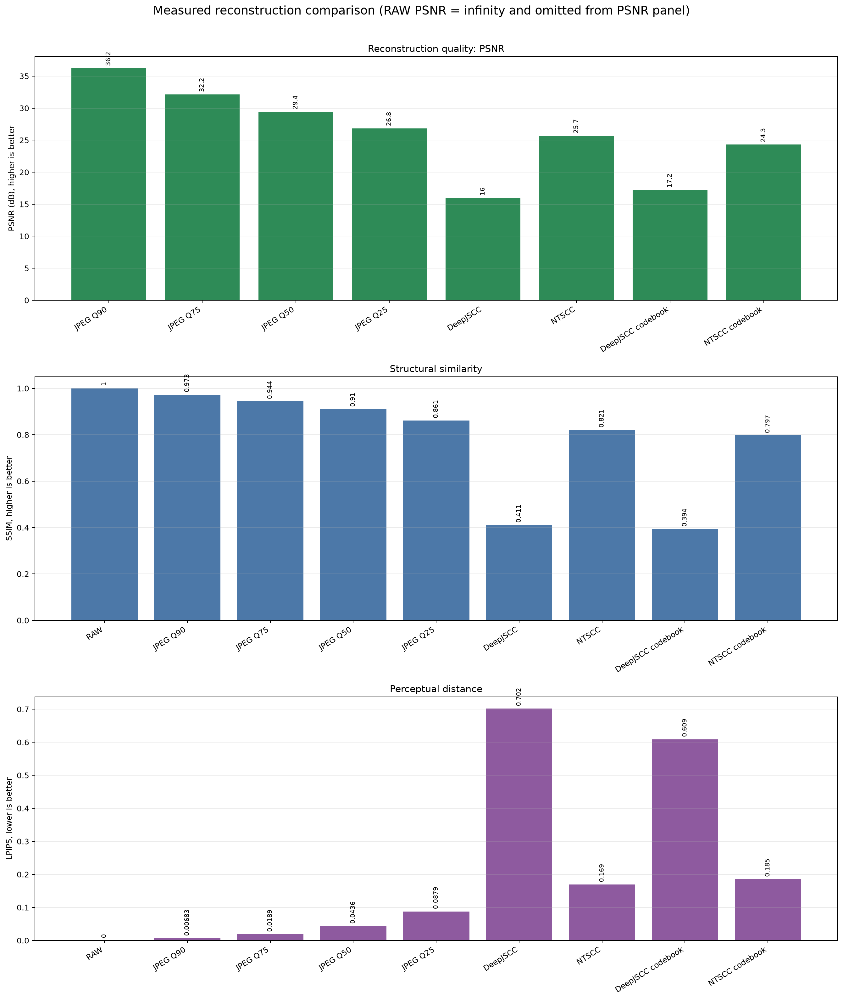

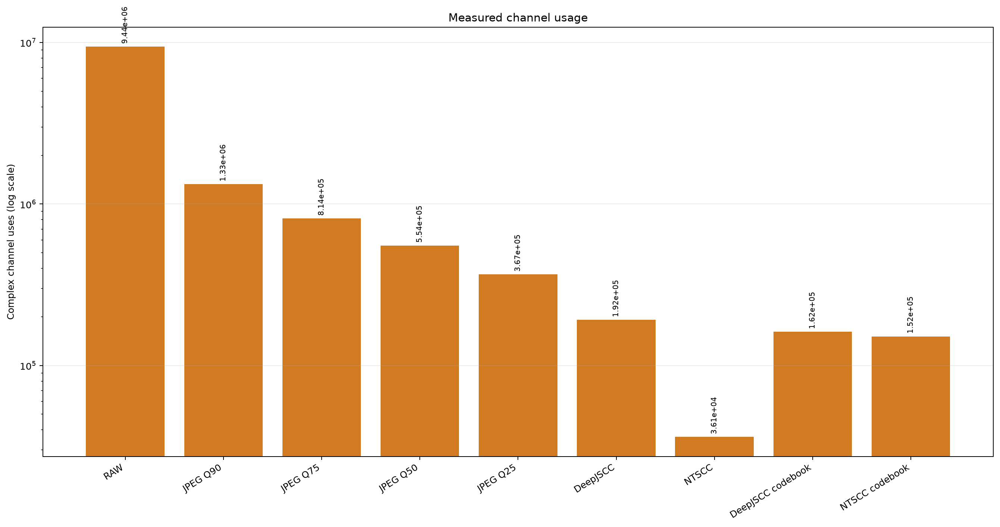

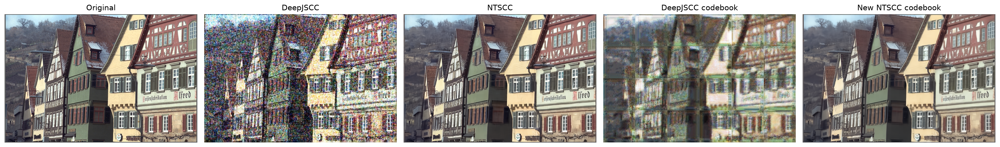

In [3]:
from IPython.display import display, Image as DisplayImage
integrated_dir = Path.cwd() / 'benchmark_outputs' / 'integrated_rate_conditioned_comparison'
integrated_kpis = pd.read_csv(integrated_dir / 'all_methods_kpi_table.csv', keep_default_na=False)
display(integrated_kpis)
display(DisplayImage(filename=str(integrated_dir / 'all_methods_quality_ssim_lpips.png')))
display(DisplayImage(filename=str(integrated_dir / 'all_methods_channel_usage.png')))
display(DisplayImage(filename=str(integrated_dir / 'all_learned_reconstructions.png')))
